# ARTI 403 – Image Processing
## Lab 1 – Basics of Programming with Python (Image Loading, Visualizing, Storing, and Arrays)

**Imam Abdulrahman Bin Faisal University — College of Computer Science and Information Technology — Department of Computer Engineering**

**Student:** Anas
**Course:** ARTI403 – Image Processing
**Academic Year:** 2026 - 2027

**Session outcome:** Explain how digital images are represented and manipulated in a computer.

This notebook follows the Lab 1 Student Procedural Manual step by step:
- Step 3/4 — Import the required libraries (OpenCV, PIL/Pillow, scikit-image, Matplotlib, NumPy)
- Task 1 — Note on the Python/NumPy cheat sheets
- Task 2 — Loading and visualizing images (OpenCV and PIL)
- Task 3 — Storing (saving) images to disk
- Task 4 — Displaying an image as a NumPy array, plus extra NumPy array operations for the Assessment section


## Step 3 & 4 — Install / Import the required libraries

The manual asks you to install: **OpenCV, scikit-image, Pillow, Matplotlib** and **NumPy**.

If you are running this on your own machine (Anaconda + Jupyter/Spyder) and a library is missing, uncomment and run the line below once in a code cell:

```
# pip install opencv-python scikit-image pillow matplotlib numpy
```

All of these libraries are already available in this environment, so we just import them below.

In [1]:
# Step 3/4: import the libraries required by the lab
import cv2                              # OpenCV
from PIL import Image                   # Pillow (PIL)
import matplotlib.pyplot as plt         # Matplotlib
import matplotlib.cm as cm
import numpy as np                      # NumPy
from skimage import data                # used only to generate the sample .tif images below

print("OpenCV version   :", cv2.__version__)
print("NumPy version    :", np.__version__)
print("All libraries imported successfully.")

OpenCV version   : 4.13.0
NumPy version    : 2.4.4
All libraries imported successfully.


## Task 1 — Exercise with Spyder

The manual asks you to practice the two cheat sheets provided in the *Resources* section (**NumPy cheat sheet** and **Python Basics cheat sheet**) inside Spyder. This is a self-practice task with no code to submit, so it is not reproduced here — open Spyder (or a plain `.py` file) and work through both cheat sheets before continuing with Task 2.

## Preparing the sample images (`images/cameraman.tif` and a second grayscale image)

The manual's Task 2 code expects two image files to already exist inside an `images/` folder:

- `images/cameraman.tif` — the classic "cameraman" test image
- `images/lena_gray_256.tif` — the classic "Lena" test image

The **cameraman** image is generated below using `skimage.data.camera()`, which is the exact same standard test image used throughout image-processing courses, and is saved as `images/cameraman.tif` so the manual's own OpenCV code works unmodified.

The classic **Lena** image is no longer distributed with scikit-image (it was removed from the library for licensing/consent reasons), so it is replaced here with another standard scikit-image grayscale sample, `skimage.data.coins()`, saved as `images/coins_gray.tif`. All the code that follows is otherwise identical to the manual — only the file name of the second image changes.

Run this cell once to create the `images/` folder used by the rest of the notebook.

In [2]:
import os

os.makedirs('images', exist_ok=True)

# Cameraman image (matches the manual's 'images/cameraman.tif')
cameraman = data.camera()                       # 512x512 uint8 grayscale
cv2.imwrite('images/cameraman.tif', cameraman)

# Second grayscale sample (substitute for 'lena_gray_256.tif', see note above)
coins = data.coins()                             # grayscale uint8
cv2.imwrite('images/coins_gray.tif', coins)

print("Saved images/cameraman.tif  ->", cameraman.shape, cameraman.dtype)
print("Saved images/coins_gray.tif ->", coins.shape, coins.dtype)

Saved images/cameraman.tif  -> (512, 512) uint8
Saved images/coins_gray.tif -> (303, 384) uint8


## Task 2 — Loading and Visualizing Images

### a. Loading / reading an image using OpenCV

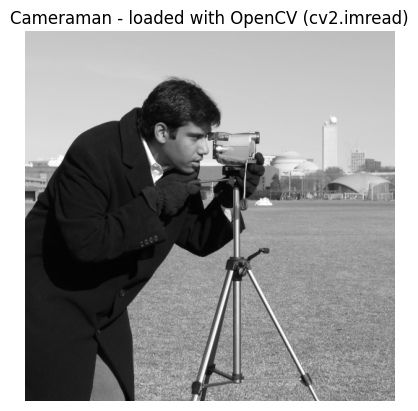

In [3]:
import cv2
img = cv2.imread('images/cameraman.tif')   # Load the image data into a NumPy array

import matplotlib.pyplot as plt
plt.imshow(img)
plt.title("Cameraman - loaded with OpenCV (cv2.imread)")
plt.axis('off')
plt.show()

**Note:** OpenCV always reads images with 3 color channels in **BGR** order (even a grayscale file gets replicated into 3 identical channels), while Matplotlib's `imshow` expects **RGB**. For a true grayscale image like `cameraman.tif` the three channels are identical, so the picture still looks correct here. For a real color photo you would need `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` before `plt.imshow`, otherwise the colors come out swapped (blue/red reversed).

### b. Loading / reading an image using PIL

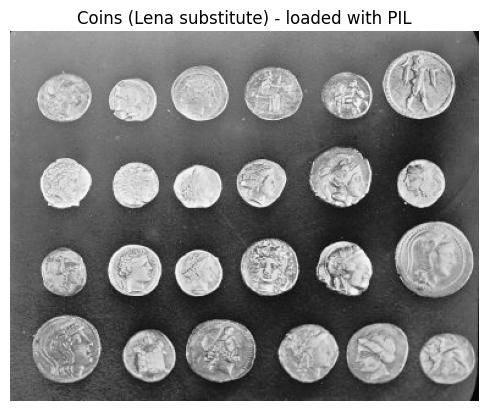

In [4]:
from PIL import Image
img2 = Image.open('images/coins_gray.tif')   # load image into a PIL Image object

import matplotlib.pyplot as plt
import matplotlib.cm as cm
plt.imshow(img2, cmap=cm.Greys_r)
plt.title("Coins (Lena substitute) - loaded with PIL")
plt.axis('off')
plt.show()

## Task 3 — Image Storing

### a. Saving an image to disk using OpenCV

In [5]:
cv2.imwrite('new_image.jpg', img)
print("Saved new_image.jpg to disk using OpenCV.")

Saved new_image.jpg to disk using OpenCV.


### b. Saving an image to disk using PIL

In [6]:
img2.save('new_image2.jpg')
print("Saved new_image2.jpg to disk using PIL.")

Saved new_image2.jpg to disk using PIL.


## Task 4 — Display image as an Array

In [7]:
print(img.shape)   # Note: img is loaded using OpenCV, so it is already a NumPy array
print(img)

(512, 512, 3)
[[[200 200 200]
  [200 200 200]
  [200 200 200]
  ...
  [189 189 189]
  [190 190 190]
  [190 190 190]]

 [[200 200 200]
  [199 199 199]
  [199 199 199]
  ...
  [190 190 190]
  [190 190 190]
  [190 190 190]]

 [[199 199 199]
  [199 199 199]
  [199 199 199]
  ...
  [190 190 190]
  [190 190 190]
  [190 190 190]]

 ...

 [[ 25  25  25]
  [ 25  25  25]
  [ 27  27  27]
  ...
  [139 139 139]
  [122 122 122]
  [147 147 147]]

 [[ 25  25  25]
  [ 25  25  25]
  [ 26  26  26]
  ...
  [158 158 158]
  [141 141 141]
  [168 168 168]]

 [[ 25  25  25]
  [ 25  25  25]
  [ 27  27  27]
  ...
  [151 151 151]
  [152 152 152]
  [149 149 149]]]


In [8]:
import numpy as np

# Convert the PIL image to a NumPy array
img_array = np.array(img2)

# Print the array
print(img_array.shape)
print(img_array)

(303, 384)
[[ 47 123 133 ...  14   3  12]
 [ 93 144 145 ...  12   7   7]
 [126 147 143 ...   2  13   3]
 ...
 [ 81  79  74 ...   6   4   7]
 [ 88  82  74 ...   5   7   8]
 [ 91  79  68 ...   4  10   7]]


## Section 4 — Assessment: NumPy array operations on the image

The manual states: *"The student will be asked to perform different operations on the array using the NumPy library."* The cells below exercise the most common ones on `img_array` (the coins image loaded with PIL) and on `cameraman`, so you can see how a digital image behaves as a plain NumPy array of pixel intensities.

In [9]:
# 1) Basic array info
print("Shape :", img_array.shape)
print("Dtype :", img_array.dtype)
print("Size (total pixels):", img_array.size)
print("Number of dimensions:", img_array.ndim)

Shape : (303, 384)
Dtype : uint8
Size (total pixels): 116352
Number of dimensions: 2


In [10]:
# 2) Pixel statistics
print("Min pixel value :", img_array.min())
print("Max pixel value :", img_array.max())
print("Mean intensity  :", img_array.mean())
print("Std deviation   :", img_array.std())

Min pixel value : 1
Max pixel value : 252
Mean intensity  : 96.85551602035204
Std deviation   : 52.87981861986824


Pixel at (0,0): 47
Pixel at (50,100): 185


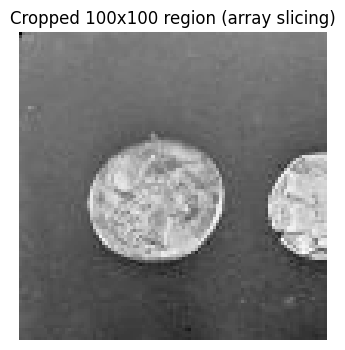

In [11]:
# 3) Indexing & slicing: read a single pixel and crop a region (ROI)
print("Pixel at (0,0):", img_array[0, 0])
print("Pixel at (50,100):", img_array[50, 100])

# Crop the top-left 100x100 region
cropped = img_array[0:100, 0:100]

plt.figure(figsize=(4, 4))
plt.imshow(cropped, cmap=cm.Greys_r)
plt.title("Cropped 100x100 region (array slicing)")
plt.axis('off')
plt.show()

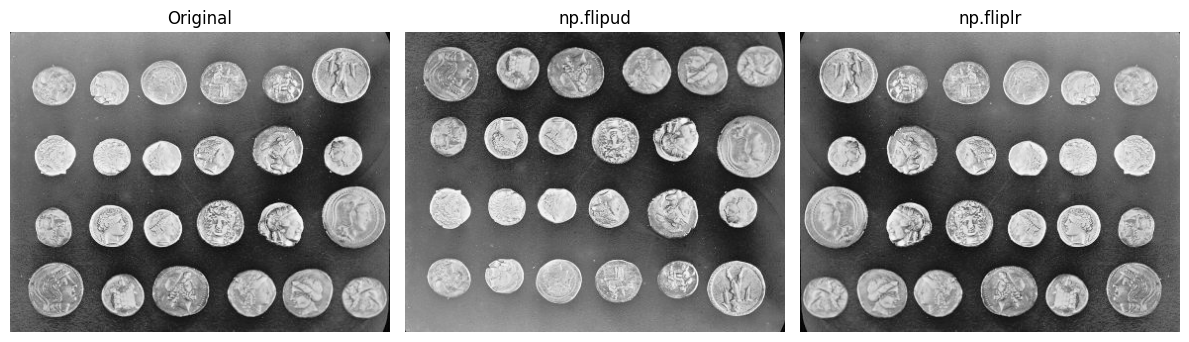

In [12]:
# 4) Flipping the image using NumPy
flipped_vertically = np.flipud(img_array)     # flip along rows (top<->bottom)
flipped_horizontally = np.fliplr(img_array)   # flip along columns (left<->right)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_array, cmap=cm.Greys_r); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(flipped_vertically, cmap=cm.Greys_r); axes[1].set_title("np.flipud"); axes[1].axis('off')
axes[2].imshow(flipped_horizontally, cmap=cm.Greys_r); axes[2].set_title("np.fliplr"); axes[2].axis('off')
plt.tight_layout()
plt.show()

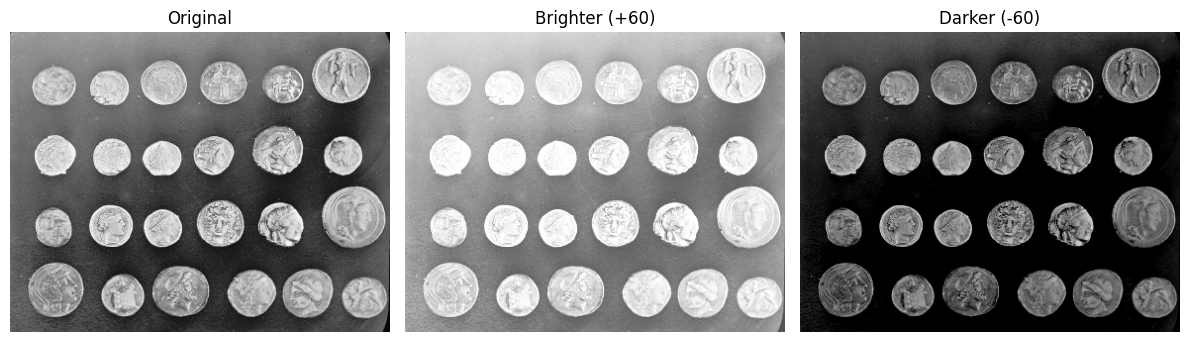

In [13]:
# 5) Arithmetic operations: brighten / darken the image
# Cast to a signed/wider type first so the addition doesn't wrap around (uint8 overflow)
brighter = np.clip(img_array.astype(np.int16) + 60, 0, 255).astype(np.uint8)
darker   = np.clip(img_array.astype(np.int16) - 60, 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img_array, cmap=cm.Greys_r, vmin=0, vmax=255); axes[0].set_title("Original"); axes[0].axis('off')
axes[1].imshow(brighter, cmap=cm.Greys_r, vmin=0, vmax=255); axes[1].set_title("Brighter (+60)"); axes[1].axis('off')
axes[2].imshow(darker, cmap=cm.Greys_r, vmin=0, vmax=255); axes[2].set_title("Darker (-60)"); axes[2].axis('off')
plt.tight_layout()
plt.show()

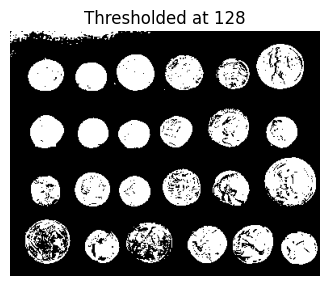

In [14]:
# 6) Simple thresholding (binarization) using boolean/NumPy indexing
threshold = 128
binary = np.where(img_array > threshold, 255, 0).astype(np.uint8)

plt.figure(figsize=(4, 4))
plt.imshow(binary, cmap=cm.Greys_r)
plt.title(f"Thresholded at {threshold}")
plt.axis('off')
plt.show()

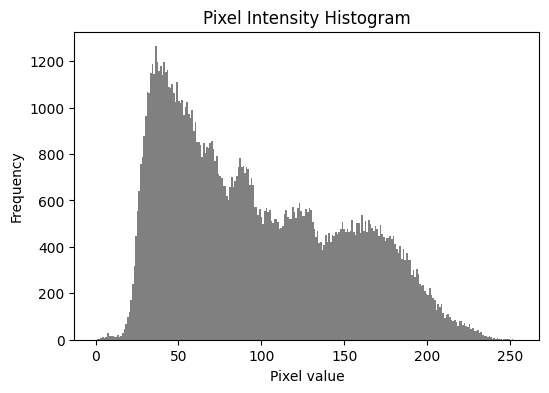

In [15]:
# 7) Histogram of pixel intensities (built with plain NumPy)
plt.figure(figsize=(6, 4))
plt.hist(img_array.ravel(), bins=256, range=(0, 255), color='gray')
plt.title("Pixel Intensity Histogram")
plt.xlabel("Pixel value")
plt.ylabel("Frequency")
plt.show()

cameraman shape: (512, 512) dtype: uint8
cameraman min/max/mean: 0 255 129.06


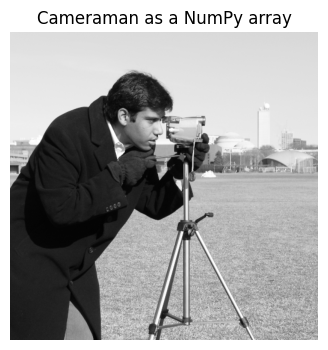

In [16]:
# 8) Same array operations quickly repeated on the cameraman image (Task 2's OpenCV image)
cam_array = np.array(cameraman)
print("cameraman shape:", cam_array.shape, "dtype:", cam_array.dtype)
print("cameraman min/max/mean:", cam_array.min(), cam_array.max(), round(cam_array.mean(), 2))

plt.figure(figsize=(4, 4))
plt.imshow(cam_array, cmap=cm.Greys_r)
plt.title("Cameraman as a NumPy array")
plt.axis('off')
plt.show()

## Conclusion

In this lab we:

1. Imported the required Python libraries (OpenCV, PIL/Pillow, scikit-image, Matplotlib, NumPy).
2. Loaded and visualized images with both OpenCV (`cv2.imread`) and PIL (`Image.open`).
3. Saved (stored) images back to disk with both libraries.
4. Displayed an image as a NumPy array and inspected its shape and contents.
5. Performed a range of NumPy array operations on the images for the Assessment section: shape/dtype/statistics, indexing & cropping, flipping, brightness arithmetic, thresholding, and histogram analysis.

This demonstrates the core lab outcome: a digital image is simply a NumPy array of pixel intensities, and every image-processing operation is ultimately an array operation.